# 6. óra: magyarázhatóság (demó)
A slide-ok számai: minden az `expl.py`-ból jön (az 5. óra `bike.py`-ja, rögzített seedek). Egy vágás, egy seed: demó.

In [1]:
import json, warnings
import pandas as pd
from expl import compute, lin_data, linear, logistic
warnings.filterwarnings('ignore')
R, X = compute()
L, G, T, S = R['linear'], R['logistic'], R['trees'], R['shap']

## Lineáris: nyers, °F, standardizált, log-cél

In [2]:
pd.DataFrame({'nyers': L['raw']['coef'], 'std (1 SD hatása)': {**L['std']['coef_per_sd'], 'const': L['std']['intercept']}, 'log-cél (b)': L['log_target']['coef'], 'exp(b)-1': L['log_target']['pct']}).round(4)

,nyers,std (1 SD hatása),log-cél (b),exp(b)-1
const,64.3292,189.4781,3.8248,44.8228
temp_C,8.3416,65.8643,0.0675,0.0699
hum_pct,-2.2480,-43.7603,-0.0199,-0.0197
wind_kmh,0.0499,0.4083,0.0040,0.0040
workingday,3.2605,1.5143,-0.0541,-0.0527
rush,183.3574,83.4856,1.2661,2.5471
yr,74.8824,37.3032,0.3307,0.3920


In [3]:
print('°C vs °F:', L['fahrenheit']); print('log-log 2x2 (lag168):', L['lag168_2x2']); print('kollinearitás:', L['collinear']); print('interakció:', L['interaction'])

°C vs °F: {'coef_temp_C': 8.341562196477868, 'coef_temp_F': 4.634201220265617, 'r2_C': 0.5149142570947035, 'r2_F': 0.5149142570947036, 'max_abs_pred_diff': 2.97859514830634e-11}
log-log 2x2 (lag168): {'level_level': 0.7481685222543536, 'level_log': 61.24715144800839, 'log_level': 0.004697439888719769, 'log_log': 0.8308282241414663, 'n': 15654, 'lag168_mean': 189.63197904688897}
kollinearitás: {'corr': 0.9872580919746136, 'temp_alone': 8.341562196477868, 'temp_with': 2.771338797480014, 'atemp_with': 5.189041663956542, 'r2_alone': 0.5149142570947035, 'r2_with': 0.5163563587535969}
interakció: {'workingday_main': 3.260460121429381, 'workingday_with_int': -59.24799619590635, 'rush_with_int': 37.37688958988532, 'rush_wd': 213.16006858575705, 'r2_with_int': 0.5762093547386647}


## Logisztikus

In [4]:
print('küszöb', G['thr'], 'prevalencia', round(G['prevalence'], 3)); pd.DataFrame({'OR (1 egység)': G['or'], 'OR (1 SD)': G['or_per_sd']}).round(3)

küszöb 281.0 prevalencia 0.249


,OR (1 egység),OR (1 SD)
temp_C,1.158,3.191
hum_pct,0.968,0.533
wind_kmh,0.994,0.954
workingday,0.716,0.856
rush,14.836,3.416
yr,3.947,1.981


In [5]:
print({k: [round(x, 3) for x in v] for k, v in G['p_examples'].items()})

{'5to6': [0.164, 0.185], '15to16': [0.461, 0.497], '30to31': [0.886, 0.9]}


## Fák: négy fontosság, zaj-oszlopok

In [6]:
pd.DataFrame({'weight': T['xgb_builtin']['weight'], 'gain': T['xgb_builtin']['gain'], 'cover': T['xgb_builtin']['cover'], 'perm (+RMSE)': T['xgb_perm'], 'perm std': T['xgb_perm_std']}).sort_values('gain', ascending=False).round(3).head(8)

,weight,gain,cover,perm (+RMSE),perm std
lag168,0.115,0.453,0.096,66.853,0.712
lag24,0.104,0.109,0.072,42.901,1.020
hr,0.090,0.082,0.098,46.617,1.468
weathersit,0.027,0.074,0.043,8.492,0.472
yr,0.014,0.053,0.105,0.000,0.000
workingday,0.021,0.045,0.049,12.735,1.903
lag2,0.095,0.034,0.071,67.814,1.200
temp,0.058,0.032,0.047,5.152,0.435


In [7]:
pd.DataFrame({'MDI': T['rf_mdi'], 'perm (+RMSE)': T['rf_perm']}).loc[['temp', 'windspeed', 'zaj_folytonos', 'zaj_azonosito']].round(4)

,MDI,perm (+RMSE)
temp,0.0052,1.4030
windspeed,0.0043,0.3579
zaj_folytonos,0.0044,0.0197
zaj_azonosito,0.0045,0.0713


## SHAP: additivitás, lineáris egyezés, példák

In [8]:
print('additivitás, legnagyobb eltérés:', S['additivity_max_abs_err']); print('LinearExplainer vs b*(x-átlag):', S['linear_check']); print('átlagos jóslat:', round(S['base'], 1))
for k, e in S['examples'].items():
    top = sorted(e['contrib'].items(), key=lambda kv: -abs(kv[1]))[:4]
    print(k, e['ts'], 'tényleges', e['y'], 'jóslat', round(e['pred'], 1), [(a, round(b)) for a, b in top])

additivitás, legnagyobb eltérés: 0.0009765625
LinearExplainer vs b*(x-átlag): {'max_abs_diff': 0.0}
átlagos jóslat: 179.3
kedd_8 2012-09-04 08:00 tényleges 632.0 jóslat 679.9 [('lag168', 276), ('lag4', 60), ('lag2', 42), ('hr', 40)]
vasarnap_3 2012-09-09 03:00 tényleges 46.0 jóslat 54.4 [('lag168', -65), ('hr', -30), ('lag24', -29), ('lag4', -14)]


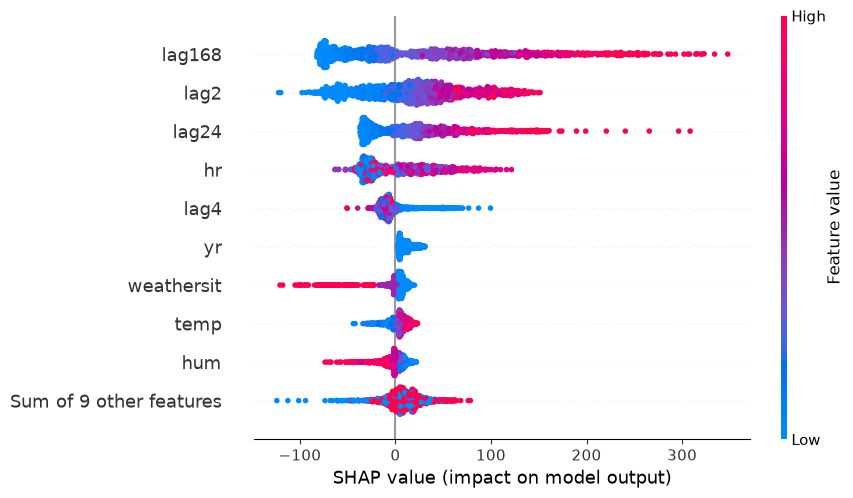

In [9]:
import shap
shap.plots.beeswarm(X['sv'], max_display=10)